In [31]:
import pandas as pd
import glob, os

In [32]:
rho_pathways = pd.read_csv('../../stats/02-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_rho_no_SWM.csv')
df = pd.read_csv('../../processed_data/01-4layers_withendo/paths_to_keep_all.csv', index_col = 0)
rho_pathways = rho_pathways[rho_pathways['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]
#filtered_pathways = pd.read_csv('../../processed_data/04a-visualisations/filtered_Stats_expanded_pathway_analysis_pval_no_SWM.csv', index_col = 0)
#sig_paths = list(filtered_pathways[filtered_pathways['sig']==True]['Unnamed: 0'])
#sig = rho_pathways[rho_pathways['Unnamed: 0'].isin(sig_paths)]

significant_paths = list(rho_pathways['Unnamed: 0'].str.split('_', expand = True)[1])

In [33]:
# layer x pathway data

files = glob.glob('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/processed_data/01-4layers_withendo/05-pathway_scoring/*.csv')
#significant
filtered = [item for item in files if any(keyword in item for keyword in significant_paths)]
#print(filtered)

for path in filtered:
    d = pd.read_csv(path, index_col = 0)
    d['region'] = d['sample_id'].str.split('_', expand = True)[1]
    d.replace({'ant':'anterior', 'mid':'middle', 'post':'posterior'}, inplace = True)
    d['layer'] = d['bayesSpace_harmony_7']+'_'+d['region']
    d = d.groupby(by=['layer']).median()
    path_name = path.split('GO_terms_')[1].split('.csv')[0]
    final = d[['score']].rename(columns = {'score' : path_name})
    if path==filtered[0]:
        final_all = final
    else:
        final_all = final_all.merge(final, left_index = True, right_index = True, how = 'inner')
    
layer_x_pathway =  final_all

In [34]:
# Load data
# layer x qMRI data

df = pd.read_csv('~/MinaRyten/Melissa/MRIxST/processed_data/02-4layers_qMRI/anon_DLPFC_AMP_qMRI_medians_4_equivol_layers.csv')
melt = pd.melt(df, id_vars = "subject_region", value_vars = ['QSM_SWM', 'QSM_L1', 'QSM_L2', 'QSM_L3', 'QSM_L4',
       'R1_SWM', 'R1_L1', 'R1_L2', 'R1_L3', 'R1_L4', 'R2s_SWM', 'R2s_L1',
       'R2s_L2', 'R2s_L3', 'R2s_L4', 'PrD_SWM', 'PrD_L1', 'PrD_L2', 'PrD_L3',
       'PrD_L4', 'MTsat_SWM', 'MTsat_L1', 'MTsat_L2', 'MTsat_L3', 'MTsat_L4'])
melt['metric'] = melt['variable'].str.split('_', expand = True)[0]
melt['layer'] = melt['variable'].str.split('_', expand = True)[1]#+'_'+melt['subject_region'].str.split('_', expand = True)[1]
melt.replace({'L1': 'SpD4', 'L2': 'SpD3', 'L3' : 'SpD2' , 'L4' : 'SpD1'}, inplace = True)
melt['layer'] = melt['layer']+'_'+melt['subject_region'].str.split('_', expand = True)[1]

grouped = melt.groupby(by=['layer', 'metric']).median().reset_index()
layer_x_qmri = grouped.pivot(index = 'layer', columns = 'metric', values = 'value')

In [35]:
genotype_df = layer_x_qmri
expression_df = layer_x_pathway

In [36]:
### Step 1: Calculate qMRI-qMRI correlation
gene_correlation = expression_df.corr(method='spearman')


In [37]:
### Step 2: Compute qMRI-pathway correlation matrix

snp_gene_corr = pd.DataFrame(index=genotype_df.columns, columns=expression_df.columns)

for snp in genotype_df.columns:
    for gene in expression_df.columns:
        rho = genotype_df[snp].corr(expression_df[gene], method='spearman')
        snp_gene_corr.loc[snp, gene] = rho


In [38]:
### Step 3: Adjust qMRI-pathway correlations using qMRI-qMRI R2

adjusted_corr = snp_gene_corr.copy()

for gene in expression_df.columns:
    r2 = gene_correlation[gene] ** 2
    avg_r2 = r2.drop(gene).mean()  # exclude self-correlation
    adjusted_corr[gene] = snp_gene_corr[gene].astype(float) * avg_r2


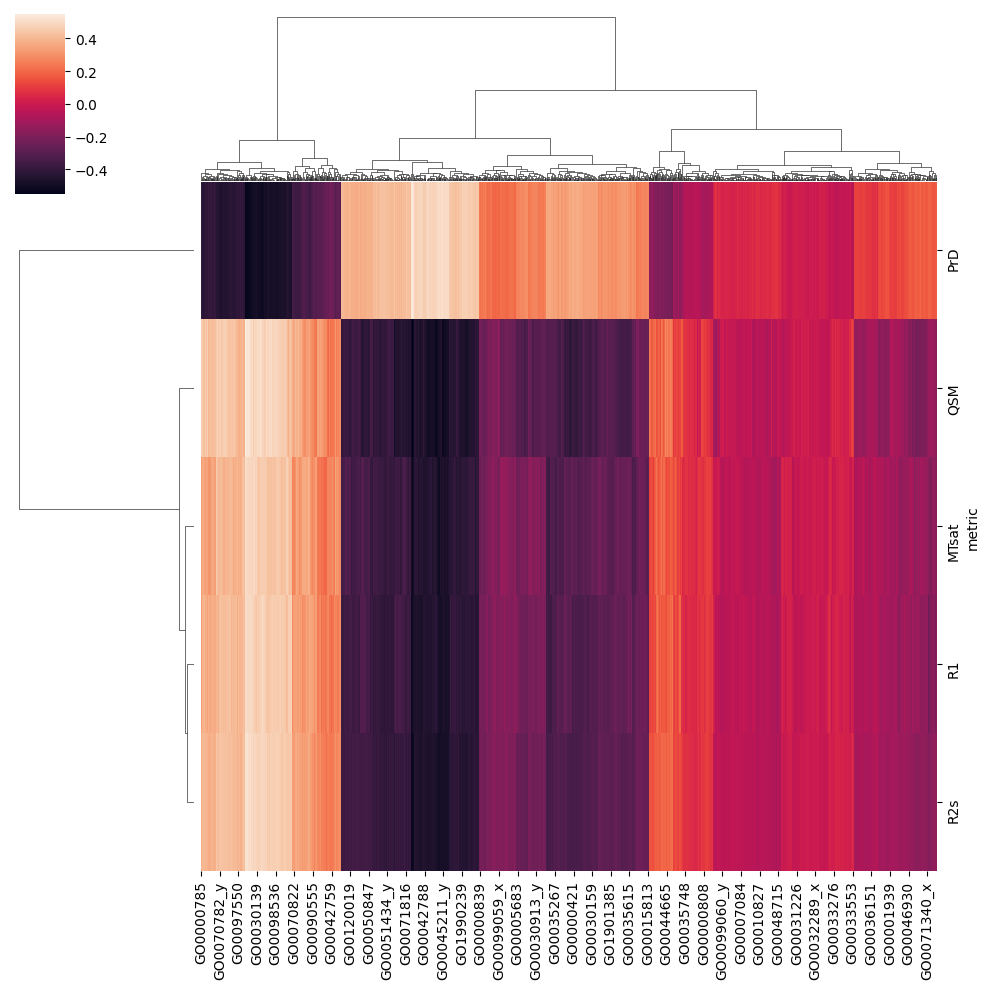

In [39]:
import seaborn as sns

sns.clustermap(adjusted_corr)

In [40]:
### Step 4: Filter by quantiles

# Flatten and filter extreme rho values
flat = adjusted_corr.stack()
filtered = flat[(flat > flat.quantile(0.999)) | (flat < flat.quantile(0.001))]


In [41]:
filtered

metric           
PrD     GO0034715    0.541274
        GO0032496   -0.537057
        GO0045923   -0.533000
        GO0055085   -0.540282
        GO0032592    0.546655
        GO0021819    0.535470
QSM     GO0071011   -0.538901
        GO0034715   -0.545375
        GO0034638    0.538139
        GO0032496    0.541157
        GO0055085    0.548791
        GO0032592   -0.550827
R2s     GO0032592   -0.534136
dtype: float64

- SNP–gene pairs with extremely high absolute rho values (post-filtering) are strong candidates for:
- Functional validation (e.g. CRISPR screens)
- Pathway enrichment
- Mapping onto known regulatory loci (e.g. enhancers from ATAC-seq or ChIP-seq)


In [44]:
import seaborn as sns
#sig.set_index('Unnamed: 0', inplace = True)
sns.clustermap(sig[['QSM','R1','R2s','PrD','MTsat']], cmap = 'viridis')

NameError: name 'sig' is not defined

In [ ]:
sig

In [45]:
sig = list(new_df[new_df['sig']==1]['Unnamed: 0'])
sig_rho = rho_pathways[rho_pathways['Unnamed: 0'].isin(sig)]
pathways = sig_rho[sig_rho['MTsat']<(sig_rho['R2s']-0.05)]
pathway_IDs = pathways['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)

print(len(pathway_name))
pathways['pathway_description'] = pathway_name

NameError: name 'new_df' is not defined

In [ ]:
rho_pathways

In [46]:
adjusted_corr

,GO0016459,GO0019897,GO0032288_x,GO0000139,GO0022624,GO0030670,GO0031663,GO0032809_x,GO0034485,GO1904504,...,GO1990112,GO0043190,GO0005834,GO0031960,GO0048788_y,GO0017121,GO0005845,GO0048179,GO0071547,GO0033270_y
metric,,,,,,,,,,,,,,,,,,,,,
MTsat,-0.013752,-0.394526,0.001490,-0.032252,-0.166683,-0.433269,0.107612,-0.462198,0.310539,-0.028787,...,-0.435664,0.076397,-0.384354,0.148927,-0.294001,0.434654,-0.043913,0.328207,0.458815,-0.003295
PrD,0.034840,0.376429,0.019373,0.038703,0.232581,0.473018,-0.175767,0.504994,-0.356415,0.035130,...,0.450559,-0.035564,0.444142,-0.152312,0.375668,-0.485790,0.038424,-0.374584,-0.504284,0.015653
QSM,-0.036673,-0.354712,-0.029805,-0.080631,-0.251963,-0.429294,0.247509,-0.487876,0.314068,-0.049767,...,-0.443111,0.023710,-0.439871,0.196313,-0.408334,0.477267,0.006587,0.403124,0.483616,-0.013182
R1,-0.036673,-0.361951,-0.010432,0.006450,-0.182189,-0.465069,0.111199,-0.483596,0.359943,-0.025371,...,-0.435664,0.043467,-0.414248,0.084618,-0.330751,0.468744,-0.062576,0.331775,0.487750,-0.020185
R2s,-0.029339,-0.369190,-0.014902,-0.019351,-0.205447,-0.449169,0.161419,-0.483596,0.328184,-0.034642,...,-0.443111,0.039516,-0.414248,0.142158,-0.343001,0.468744,-0.037326,0.360314,0.483616,-0.011534
